# Agent benchmark example: the winner's curse

- This notebook measures the winner's curse when picking the best of K agent
  configs on a benchmark of N tasks with S seeds per task
- It runs a small sweep live, then reads the full sweep saved in
  `agent_benchmark_results/` (1000 replications per setting, seed 0)
- The pedagogical arc:
  - Run a sweep over (K, N, S) and read its table
  - See how big the curse is and how often the winner is truly best
  - Compare the two ways to re-evaluate the winner
  - Check how often bootstrap intervals cover the true rate
  - List the assumptions that could make a real benchmark behave differently

In [1]:
%load_ext autoreload
%autoreload 2

import logging
import os

import pandas as pd

In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook
import helpers.hprint as hprint

import agent_benchmark_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

# Part 1: Running a sweep

## Cell 1.1: A small sweep

- Each setting (K, N, S) runs independent replications of one benchmark run
- Each setting has its own seed derived from the batch seed, so a setting gives
  the same result whatever other settings run with it

In [3]:
# Run a small sweep with 200 replications per setting.
base = utils.SimParams()
n_reps_small = 200
seed = 0
df_small = utils.run_curse_sweep(
    base,
    n_reps_small,
    seed,
    n_configs_grid=(3, 10),
    n_tasks_grid=(25, 100),
    n_seeds_grid=(1, 3),
)
display(df_small[["n_configs", "n_tasks", "n_seeds", "curse", "curse_se"]])
# Outcome: 8 settings, with the largest curse at K = 10, N = 25, S = 1.

Curse sweep:   0%|          | 0/8 [00:00<?, ?it/s]

Curse sweep:  12%|#2        | 1/8 [00:00<00:03,  1.82it/s]

Curse sweep:  25%|##5       | 2/8 [00:01<00:02,  2.01it/s]

Curse sweep:  38%|###7      | 3/8 [00:01<00:02,  2.05it/s]

Curse sweep:  50%|#####     | 4/8 [00:01<00:01,  2.06it/s]

...

Curse sweep:  75%|#######5  | 6/8 [00:02<00:00,  2.13it/s]

Curse sweep:  88%|########7 | 7/8 [00:03<00:00,  2.16it/s]

Curse sweep: 100%|##########| 8/8 [00:03<00:00,  2.09it/s]

Curse sweep: 100%|##########| 8/8 [00:03<00:00,  2.08it/s]

,n_configs,n_tasks,n_seeds,curse,curse_se
0,3,25,1,0.053262,0.006155
1,3,25,3,0.037014,0.004827
2,3,100,1,0.030735,0.003109
3,3,100,3,0.013962,0.002632
4,10,25,1,0.106992,0.005049
5,10,25,3,0.074948,0.004375
6,10,100,1,0.046218,0.002660
7,10,100,3,0.030537,0.002470


## Cell 1.2: Regenerating the full sweep

- The full sweep has 64 settings for the curse and 16 for coverage, and takes
  about 5 minutes on one core
- Set `rerun_sweeps = True` to regenerate the saved CSV files

In [4]:
# Set the parameters that produced the saved results.
results_dir = "agent_benchmark_results"
n_reps = 1000
n_coverage_reps = 400
n_boot = 500
coverage_k = 5
print("n_reps=", n_reps)
print("n_coverage_reps=", n_coverage_reps)
# Outcome: the same values as the defaults of `run_and_save_sweeps()`.

n_reps= 1000
n_coverage_reps= 400


In [5]:
# Regenerate the saved results only when asked.
rerun_sweeps = False
if rerun_sweeps:
    utils.run_and_save_sweeps(
        results_dir,
        n_reps=n_reps,
        n_coverage_reps=n_coverage_reps,
        n_boot=n_boot,
        coverage_k=coverage_k,
        seed=seed,
    )
print("rerun_sweeps=", rerun_sweeps)
# Outcome: the saved CSV files are used as they are.

rerun_sweeps= False


In [6]:
hintros.print_obj_info(utils.run_and_save_sweeps)

- `run_and_save_sweeps(dst_dir: str, *, n_reps: int = 1000, n_coverage_reps: int = 400, n_boot: int = 500, coverage_k: int = 5, seed: int = 0) -> None`  
  Run both sweeps with the default model and save them as CSV files...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/agent_benchmark_utils.py#L760


## Cell 1.3: The full sweep

In [7]:
# Load the full curse sweep.
df_curse = pd.read_csv(os.path.join(results_dir, "curse_sweep.csv"))
print("df_curse.shape=", df_curse.shape)
display(df_curse.head())
# Outcome: 64 rows, one per (K, N, S), with each metric and its Monte Carlo
# standard error.

df_curse.shape= (64, 17)


,n_configs,n_tasks,n_seeds,curse,curse_se,is_truly_best,is_truly_best_se,regret,regret_se,rank_error,rank_error_se,fresh_seed_error,fresh_seed_error_se,fresh_task_error,fresh_task_error_se,extra_runs,extra_cost_frac
0,3,25,1,0.063378,0.002663,0.452,0.015746,0.014710,0.000624,0.736333,0.015310,0.013098,0.002891,0.000458,0.003060,25.0,0.333333
1,3,25,3,0.035980,0.002128,0.549,0.015743,0.011427,0.000570,0.626667,0.015498,0.011113,0.002332,-0.003980,0.002305,75.0,0.333333
2,3,25,5,0.031171,0.002026,0.561,0.015701,0.010470,0.000539,0.600333,0.015915,0.013947,0.002065,-0.003637,0.002194,125.0,0.333333
3,3,25,10,0.026142,0.001982,0.562,0.015697,0.009746,0.000509,0.585333,0.015658,0.017166,0.002033,0.002514,0.002156,250.0,0.333333
4,3,50,1,0.043739,0.001855,0.509,0.015817,0.012326,0.000562,0.658333,0.015299,0.006439,0.002156,-0.000121,0.002170,50.0,0.333333


In [8]:
# Load the full coverage sweep.
df_cov = pd.read_csv(os.path.join(results_dir, "coverage_sweep.csv"))
print("df_cov.shape=", df_cov.shape)
display(df_cov.head())
# Outcome: 32 rows, one per (N, S, method), at K = 5.

df_cov.shape= (32, 7)


,n_tasks,n_seeds,method,coverage,coverage_se,mean_width,n_intervals
0,25,1,task,0.9335,0.005571,0.362790,2000
1,25,1,task_seed,0.9260,0.005853,0.362079,2000
2,25,3,task,0.9235,0.005943,0.284376,2000
3,25,3,task_seed,0.9530,0.004732,0.314259,2000
4,25,5,task,0.9400,0.005310,0.267270,2000


# Part 2: The winner's curse

## Cell 2.1: Size of the curse

**Goal**
- See how far the winner's observed score is above its true rate
  $\bar{Y}_A$
- Compare more candidates K against more tasks N and more seeds S

**Description**
- Inputs
  - `df_curse`: the full curse sweep
- Panels
  - Top row: the winner's score minus its true rate, against N, one line per K
  - Bottom row: the same for a re-evaluation of the winner on fresh tasks
  - Columns: S = 1, 3, 5, 10 seeds

In [9]:
# Describe the set-up of the sweep, to show it under each plot title.
setup_txt = utils.describe_sweep_setup(base, n_reps)
print("setup_txt=", setup_txt)
# Outcome: the model parameters and the number of replications.

setup_txt= mu_theta=1.0, sigma_theta=0.2, mu_b=0.0, sigma_b=2.0, sigma_u=1.0, 1000 replications per setting


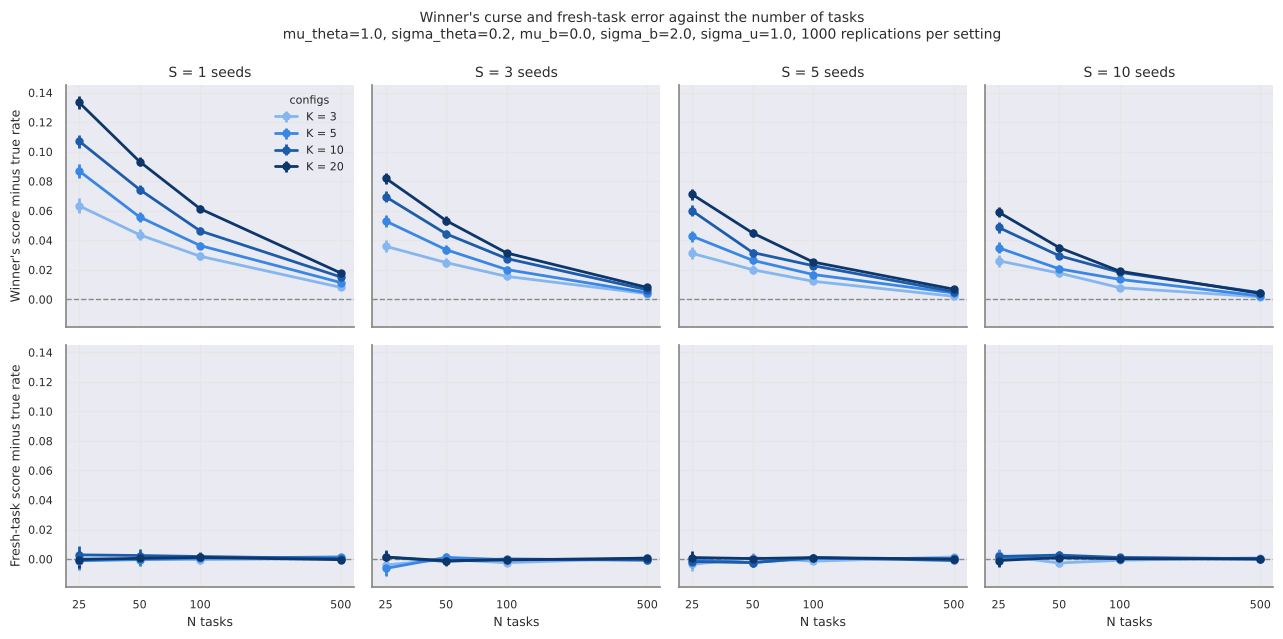

In [10]:
# Plot the curse and the fresh-task error against N.
utils.plot_curse(df_curse, setup_txt, figsize=(13, 6.5))

**Guided usage**
- Look at the top row
  - Observe every point above the dashed zero line: the curse is positive in
    all 64 settings
  - Observe the lines go down as N grows, in every panel
  - Observe the lines move up from K = 3 to K = 20, except at N = 500 and
    S = 10, where K = 10 and K = 20 are within noise of each other
- Compare the same panel across columns
  - Observe that more seeds lower the curse less than more tasks do
- Look at the bottom row
  - Observe the lines close to the zero line: 59 of the 64 error bars cross
    zero, so fresh tasks remove the curse

**Implementation** `plot_curse(df, setup_txt, figsize=None)`
- Draws a 2 by 4 grid of panels, one column per S
- Draws one line per K with 95% error bars from the precomputed standard
  errors, via `_plot_lines_by()`
- Uses a log x axis with ticks at the N values of the grid, via `_style_axis()`
- Puts the set-up of the sweep under the title

In [11]:
hintros.print_obj_info(utils.plot_curse)

- `plot_curse(df: pandas.DataFrame, setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot the winner's curse and the fresh-task error against N...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/agent_benchmark_utils.py#L894


## Cell 2.2: The curse in numbers

- Some settings from the sweep, in points of resolve rate:
  - K = 10, N = 100, S = 3: 2.8 points too high
  - K = 20, N = 25, S = 1: 13.3 points too high
  - K = 3, N = 500, S = 10: 0.2 points too high
- At K = 10 and S = 3, going from 25 to 500 tasks cuts the curse from 7.0 to
  0.6 points
- At K = 10 and N = 25, going from 1 to 10 seeds cuts it from 10.7 to 4.9
  points

In [12]:
# Show the curse at K = 10 for every (N, S), in points.
n_configs = 10
df_k10 = df_curse[df_curse["n_configs"] == n_configs]
print("kept=", hprint.perc(len(df_k10), len(df_curse)))
display(100 * df_k10.pivot(index="n_tasks", columns="n_seeds", values="curse"))
# Outcome: 16 of the 64 rows are kept, and the curse falls along both axes,
# faster along N.

kept= 16 / 64 = 25.00%


n_seeds,1,3,5,10
n_tasks,,,,
25,10.724060,6.954701,6.001139,4.873858
50,7.437963,4.438269,3.173014,2.953643
100,4.636407,2.765732,2.282212,1.832126
500,1.515257,0.643770,0.519304,0.453637


## Cell 2.3: Tasks against seeds at the same budget

- The grid has 8 groups of settings with the same K and the same runs per
  config N S, i.e., 250 or 500
- In all 8 groups, the setting with more tasks has the smaller curse
  - E.g., at K = 10, N = 500, S = 1 gives 1.5 points and N = 50, S = 10 gives
    3.0 points

In [13]:
# Compare settings with the same K and the same runs per config.
df_budget = df_curse.assign(runs=df_curse["n_tasks"] * df_curse["n_seeds"])
mask = df_budget.duplicated(["n_configs", "runs"], keep=False)
df_budget = df_budget[mask].sort_values(["n_configs", "runs", "n_tasks"])
print("kept=", hprint.perc(len(df_budget), len(df_curse)))
display(df_budget[["n_configs", "runs", "n_tasks", "n_seeds", "curse"]])
# Outcome: 20 of the 64 settings share their K and runs per config with
# another setting, and within each group the curse goes down as N goes up.

kept= 20 / 64 = 31.25%


,n_configs,runs,n_tasks,n_seeds,curse
3,3,250,25,10,0.026142
6,3,250,50,5,0.020089
7,3,500,50,10,0.017788
10,3,500,100,5,0.012242
12,3,500,500,1,0.008104
19,5,250,25,10,0.034935
22,5,250,50,5,0.026439
23,5,500,50,10,0.020681
26,5,500,100,5,0.016839
28,5,500,500,1,0.011378


# Part 3: Picking the right config

## Cell 3.1: Probability that the winner is truly best

**Goal**
- See how often the observed winner is the config with the highest $\bar{Y}_A$

**Description**
- Inputs
  - `df_curse`: the full curse sweep
- Panels
  - One panel per S, with the probability against N, one line per K

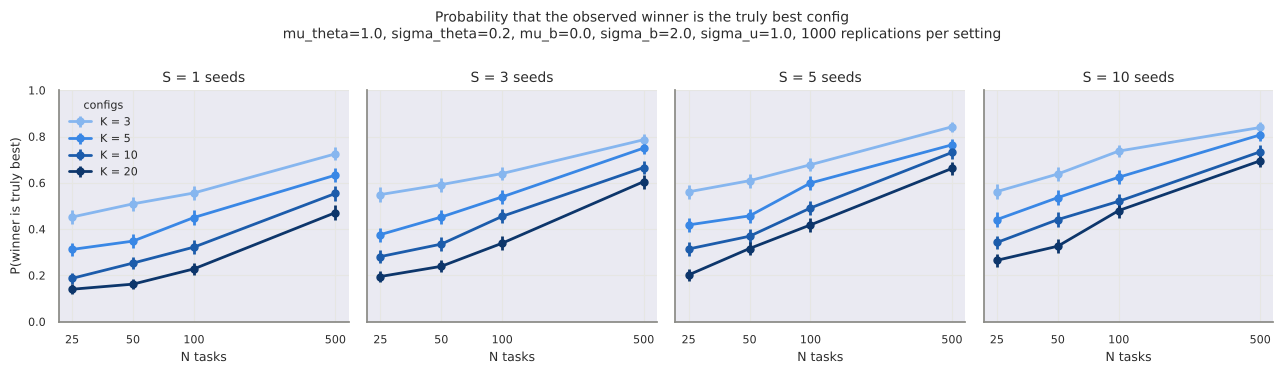

In [14]:
# Plot the probability that the winner is the truly best config.
utils.plot_prob_best(df_curse, setup_txt, figsize=(13, 3.8))

**Guided usage**
- Look at K = 10, N = 100, S = 3
  - Observe that the winner is truly best 45.5% of the time
- Look at the largest setting, K = 20, N = 500, S = 10
  - Observe that it is still right only 69.5% of the time

**Implementation** `plot_prob_best(df, setup_txt, figsize=None)`
- Draws one panel per S, one line per K, via `_plot_lines_by()`
- Fixes the y axis to $[0, 1]$
- Puts the set-up of the sweep under the title

In [15]:
hintros.print_obj_info(utils.plot_prob_best)

- `plot_prob_best(df: pandas.DataFrame, setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot the probability that the observed winner is the truly best config...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/agent_benchmark_utils.py#L953


## Cell 3.2: Cost of a wrong pick

- When the winner is wrong, the loss is small, since the configs are close
- Rankings below the top are noisy

In [16]:
# Show regret and rank error at two settings, in points and places.
idx = ["n_configs", "n_tasks", "n_seeds"]
df_pick = df_curse.set_index(idx).loc[[(10, 100, 3), (20, 25, 1)]]
df_pick = df_pick.assign(regret_points=100 * df_pick["regret"])
display(df_pick[["is_truly_best", "regret_points", "rank_error"]])
# Outcome:
# - At K = 10, N = 100, S = 3 the winner's true rate is 1.1 points below the
#   best on average
# - At K = 20, N = 25, S = 1 each config's rank is off by 5.4 places on average

,,,is_truly_best,regret_points,rank_error
n_configs,n_tasks,n_seeds,,,
10,100,3,0.455,1.114601,1.77000
20,25,1,0.140,3.358845,5.42565


# Part 4: Fixing the curse

## Cell 4.1: Fresh tasks

- Rerunning the winner on N fresh tasks with S seeds gives an unbiased estimate
  of its true rate
- The cost is N S extra runs, i.e., 1 / K of the original search

In [17]:
# Pool the fresh-task error over all 64 settings.
fresh_task_mean = df_curse["fresh_task_error"].mean()
# 2.58 is the two-sided 99% critical value of a standard normal.
z_crit = 2.58
z = df_curse["fresh_task_error"] / df_curse["fresh_task_error_se"]
n_beyond = int((z.abs() > z_crit).sum())
print("fresh_task_mean=", fresh_task_mean)
print("n_beyond=", n_beyond)
# Outcome: the mean error is about -0.00002, and 1 of 64 settings is beyond
# 2.58 standard errors from zero, about what chance gives.

fresh_task_mean= -2.3920521752261975e-05
n_beyond= 1


## Cell 4.2: Fresh seeds on the same tasks

- Rerunning the winner on the same tasks with new seeds removes only part of
  the curse
- The winner was also selected for its luck on these tasks (the $u_{ki}$
  terms), and new seeds keep that luck
- With more seeds, more of the curse comes from task luck and less from seed
  luck

In [18]:
# Compute the share of the curse that fresh seeds remove at K = 10.
removed = 1 - df_k10["fresh_seed_error"] / df_k10["curse"]
df_removed = df_k10.assign(removed=removed).pivot(
    index="n_tasks", columns="n_seeds", values="removed"
)
display(df_removed)
# Outcome: fresh seeds remove 85% to 92% of the curse at S = 1, but only 27%
# to 38% at S = 10.

n_seeds,1,3,5,10
n_tasks,,,,
25,0.859749,0.666408,0.534832,0.376375
50,0.897289,0.689909,0.607372,0.366327
100,0.922266,0.673601,0.556215,0.270014
500,0.851869,0.770254,0.541417,0.358701


# Part 5: Error bars

## Cell 5.1: Coverage of bootstrap intervals

**Goal**
- Check how often a 95% bootstrap interval on one config's score contains its
  true rate $\bar{Y}_A$

**Description**
- Inputs
  - `df_cov`: the full coverage sweep, at K = 5
- Panels
  - `Resample tasks`: coverage against N, one line per S
  - `Resample tasks, then seeds`: the same for the two-stage scheme
  - The dashed line is the nominal 95%

In [19]:
# Describe the set-up of the coverage sweep.
setup_cov_txt = utils.describe_sweep_setup(base, n_coverage_reps)
setup_cov_txt += f", K = {coverage_k}, {n_boot} bootstrap draws per interval"
print("setup_cov_txt=", setup_cov_txt)
# Outcome: the model parameters, the replications, K, and the bootstrap draws.

setup_cov_txt= mu_theta=1.0, sigma_theta=0.2, mu_b=0.0, sigma_b=2.0, sigma_u=1.0, 400 replications per setting, K = 5, 500 bootstrap draws per interval


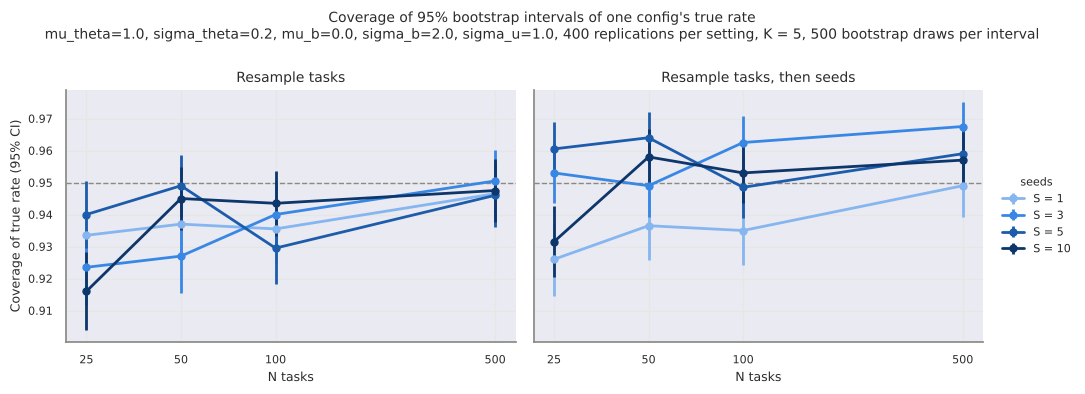

In [20]:
# Plot the coverage of both resampling schemes.
utils.plot_coverage(df_cov, setup_cov_txt, figsize=(11, 4))

**Guided usage**
- Look at `Resample tasks`
  - Observe the lines below 95% for small N, and close to 95% at N = 500
- Look at `Resample tasks, then seeds`
  - Observe the lines mostly above the task-only lines, since the intervals
    are wider

**Implementation** `plot_coverage(df, setup_txt, figsize=None)`
- Draws one panel per resampling scheme, one line per S, via
  `_plot_lines_by()`
- Draws the nominal 95% as a dashed line
- Does not force the y axis to $[0, 1]$, since coverage stays between 0.9 and
  1 and the full range would squash the lines
- Puts the set-up of the sweep under the title

In [21]:
hintros.print_obj_info(utils.plot_coverage)

- `plot_coverage(df: pandas.DataFrame, setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot bootstrap CI coverage of the true `Ybar_A` against N...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/agent_benchmark_utils.py#L997


## Cell 5.2: Coverage in numbers

In [22]:
# Average coverage of each scheme for small and large N.
n_tasks_large = 500
df_cov_n = df_cov.assign(large_n=df_cov["n_tasks"] == n_tasks_large)
df_cov_n = df_cov_n.groupby(["method", "large_n"])["coverage"]
display(df_cov_n.agg(["mean", "min", "max"]))
# Outcome:
# - Resampling tasks covers 93.5% on average for N from 25 to 100 and 94.8% at
#   N = 500
# - Resampling tasks then seeds covers 94.8% and 95.8%, from 92.6% to 96.75%

mean    min     max
method    large_n                         
task      False    0.934958  0.916  0.9490
          True     0.947625  0.946  0.9505
task_seed False    0.948125  0.926  0.9640
          True     0.958125  0.949  0.9675

- Resampling tasks undercovers by about 1.5 points for small N
  - That matches the known small-sample bias of the percentile bootstrap, but
    the cause was not checked here
- The two-stage scheme is not the right method just because it is closer to
  95%
  - With S = 1 it is the same as task resampling
  - With iid outcomes it overcovers (98% in the tests) because it counts seed
    noise twice
  - In this model the extra width happens to cancel the small-N undercoverage
- The coverage standard errors treat the K intervals of one replication as
  independent
  - They share the same tasks, so the real standard errors are a bit larger

# Part 6: Limits of the model

## Cell 6.1: Assumptions that could make a real benchmark behave differently

- Task difficulty is Normal on the logit scale
  - Real per-task results are often bimodal, with many tasks solved by every
    config or by none
- $u_{ki}$ is independent across tasks
  - Real agents fail in correlated ways, e.g., one scaffold breaks on every
    task from the same repository
- Seeds are independent Bernoulli draws
  - Real reruns can share cached state, rate limits, or flaky test
    environments
- Configs are drawn independently with one skill spread
  - A real scaffold search produces variants of one agent whose interactions
    $u_{ki}$ are correlated, which shrinks the task-luck part of the curse
- The selection rule is a plain argmax over all K at once
  - Real searches are often sequential and adaptive, which can make the curse
    larger
- Real benchmarks have a fixed task set, e.g., 500 tasks for SWE-bench
  Verified
  - Fresh tasks may not exist, and then fresh seeds are the only fix
    available, with the limits shown in Part 4
- All parameter values are guesses
  - The next step is to fit `sigma_theta`, `sigma_b`, and `sigma_u` to real
    per-task, per-seed results